In [1]:
# brief
# get_mel_spectrogram	Converts audio waveform to Mel spectrogram
# prepare_text	Converts text input to phonemes
# diffusion_schedule	Defines noise schedule for diffusion process
# forward_process	Adds noise to audio data
# denoise_step	Removes noise using a neural network
# Generator	U-Net like structure for generating speech
# Discriminator	Evaluates generated speech quality
# adversarial_loss	Loss function for GAN training
# diffusion_loss	Loss function for noise prediction
# train_step	Performs one training step for both Generator and Discriminator

#LibSpeech dataset

# Text Processing: Handles the conversion of input text into suitable features for the model.​
# arXiv
# +1
# ResearchGate
# +1

# Acoustic Model: Implements the model that maps text features to mel-spectrograms.​

# Diffusion Decoder: Contains the diffusion model enhanced with GAN training for high-fidelity spectrogram generation.​

# Vocoder: Utilizes models like HiFi-GAN to synthesize waveforms from mel-spectrograms.

# Fix: You must train for many epochs (e.g. thousands of steps) before realistic speech appears. Otherwise, the generator just outputs random Mel values, and Griffin-Lim turns that into “static.”

Tutorials
https://github.com/keonlee9420/DiffGAN-TTS
https://pytorch.org/tutorials/beginner/dcgan_faces_tutorial.html

In [2]:
# Core Parts of a DiffGAN-TTS-style TTS system:
# Text Encoder – Turns input text into embeddings.

# Acoustic Predictor (e.g. mel-spectrogram generator) – Uses a diffusion model + GAN to predict a mel-spectrogram.

# Vocoder – Converts mel-spectrogram to waveform (e.g., use pre-trained HiFi-GAN or similar).

# For real speech, expect 50–100+ mel frames for a 1–2 second utterance.

# Positional encodings

# Attention-based duration predictor or aligner

# HiFi-GAN or other neural vocoder



In [3]:
# Steps to train with dataset
# Load LibriSpeech Dataset (via torchaudio)

# Text Preprocessing (convert transcript to token IDs)

# Audio Preprocessing (convert waveform to mel-spectrogram)

# Batch and Feed to Model

# Train using your train loop

In [4]:
# Load one .wav file

# Get its transcript

# Convert it to token sequence and mel-spectrogram

# Pass it through your DiffGAN_TTS model

# See if it outputs something reasonable

# Predict duration explicitly (later)
# Once your architecture is upgraded to match true DiffGAN-TTS, you’ll want to:

# Add a length regulator / duration model

# Expand text → target length mel spectrogram

In [5]:
import torch
import torchaudio
import torch.nn as nn
import torch.nn.functional as F
import string
import torchaudio.transforms as T
from torch.utils.data import Dataset, DataLoader
import torch.nn.utils.rnn as rnn_utils
import pandas as pd
import os
import matplotlib.pyplot as plt
import math

In [6]:
#PreProcessing Funcs
CHAR_VOCAB = {c: i+1 for i, c in enumerate(string.ascii_lowercase + " '")}
CHAR_VOCAB["<pad>"] = 0

def text_to_sequence(text):
    return [CHAR_VOCAB.get(c, 0) for c in text.lower() if c in CHAR_VOCAB]

In [7]:
mel_transform = T.MelSpectrogram(
    sample_rate=16000,
    n_fft=1024,
    hop_length=256,
    n_mels=80
)

def waveform_to_mel(waveform):
    mel = mel_transform(waveform)
    mel_db = torchaudio.transforms.AmplitudeToDB()(mel)
    return mel_db.squeeze(0).transpose(0, 1)  # (Time, Mel)

In [8]:
# --- Load one file ---
# metadata_path = 'LJSpeech-1.1\LJSpeech-1.1\metadata.csv'
metadata_path = r"LJSpeech-1.1\LJSpeech-1.1\metadata.csv"

df = pd.read_csv(metadata_path, sep='|', header=None, names=["file_id", "text", "normalized_text"])

# Example sample
file_id = df.iloc[0]["file_id"]
text = df.iloc[0]["normalized_text"]
wav_path = os.path.join("LJSpeech-1.1/LJSpeech-1.1/wavs", f"{file_id}.wav")

# --- Preprocess ---
waveform, sample_rate = torchaudio.load(wav_path)
text_seq = torch.tensor([text_to_sequence(text)])  # (1, seq_len)
mel = waveform_to_mel(waveform)                    # (time, mel)

print("Text:", text)
print("Input tokens:", text_seq.shape)
print("Mel target shape:", mel.shape)


Text: Printing, in the only sense with which we are at present concerned, differs from most if not from all the arts and crafts represented in the Exhibition
Input tokens: torch.Size([1, 149])
Mel target shape: torch.Size([832, 80])


In [9]:
# class LibriSpeechTTS(Dataset):
#     def __init__(self, subset):
#         self.data = LIBRISPEECH("C:\Users\spenc\OneDrive\Documents\QMUL Documents\ECS7013P\Project Ideas\Assignment 1\LJSpeech-1.1\LJSpeech-1.1\wavs", url=subset, download=True)

#     def __getitem__(self, idx):
#         waveform, sr, text, *_ = self.data[idx]
#         text_seq = torch.tensor(text_to_sequence(text))
#         mel = waveform_to_mel(waveform)
#         return text_seq, mel

#     def __len__(self):
#         return len(self.data)

# def collate_fn(batch):
#     texts, mels = zip(*batch)

#     text_lens = torch.tensor([len(t) for t in texts])
#     mel_lens = torch.tensor([len(m) for m in mels])

#     padded_texts = rnn_utils.pad_sequence(texts, batch_first=True)
#     padded_mels = rnn_utils.pad_sequence(mels, batch_first=True)

#     return padded_texts, padded_mels, text_lens, mel_lens

class SimpleLJSDataset(Dataset):
    def __init__(self, metadata_path, wav_dir, max_items=20):
        self.data = pd.read_csv(metadata_path, sep='|', header=None, names=["file_id", "text", "_"])
        self.data = self.data.iloc[:max_items]
        self.wav_dir = wav_dir

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        text = row["text"]
        file_id = row["file_id"]
        wav_path = os.path.join(self.wav_dir, f"{file_id}.wav")
        waveform, _ = torchaudio.load(wav_path)
        text_seq = torch.tensor(text_to_sequence(text), dtype=torch.long)
        mel = waveform_to_mel(waveform)
        return text_seq, mel

    def __len__(self):
        return len(self.data)



In [10]:
def collate_fn(batch):
    texts, mels = zip(*batch)
    text_lens = [len(t) for t in texts]
    mel_lens = [len(m) for m in mels]
    texts_padded = rnn_utils.pad_sequence(texts, batch_first=True)
    mels_padded = rnn_utils.pad_sequence(mels, batch_first=True)
    return texts_padded, mels_padded, torch.tensor(text_lens), torch.tensor(mel_lens)


In [11]:
def get_noise_schedule(num_steps=1000, schedule_type="cosine"):
    if schedule_type == "linear":
        return torch.linspace(1e-4, 0.02, num_steps)  # linear beta schedule
    elif schedule_type == "cosine":
        steps = torch.arange(num_steps + 1, dtype=torch.float32) / num_steps
        alphas_cumprod = torch.cos((steps + 0.008) / 1.008 * math.pi / 2) ** 2
        alphas_cumprod = alphas_cumprod / alphas_cumprod[0]
        betas = 1 - (alphas_cumprod[1:] / alphas_cumprod[:-1])
        return torch.clip(betas, 1e-6, 0.999)


Added in a learned duration predictor, regulator that expands text features to mel length, model shoul now be able to generate outputs with T ≈ 800 mel frames

In [19]:
# -----------------------
# TEXT ENCODER
# -----------------------
class TextEncoder(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)

    def forward(self, x):
        x = self.embedding(x)  # (B, T_text, E)
        out, _ = self.lstm(x)
        return out  # (B, T_text, H)
    
# -----------------------
# DIFFUSION BLOCK (Simplified)
# -----------------------
class DiffusionBlock(nn.Module):
    def __init__(self, mel_dim, hidden_dim, diffusion_steps=1000, schedule_type="cosine"):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(mel_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, mel_dim)
        )
        self.betas = get_noise_schedule(diffusion_steps, schedule_type)
        self.alphas = 1.0 - self.betas
        self.alpha_bars = torch.cumprod(self.alphas, dim=0)  # used for scaling

    def forward(self, x, t, add_noise=True):
        if add_noise:
            # get alpha_bar[t], shape-match with x
            alpha_bar = self.alpha_bars[t].to(x.device)  # scalar
            noise = torch.randn_like(x)
            x = torch.sqrt(alpha_bar) * x + torch.sqrt(1 - alpha_bar) * noise
        return self.mlp(x)

    

# -----------------------
# GENERATOR (Mel Generator)
# -----------------------
class MelGenerator(nn.Module):
    def __init__(self, hidden_dim, mel_dim, diffusion_steps=10):
        super().__init__()
        self.diffusion_blocks = nn.ModuleList(
            [DiffusionBlock(mel_dim, hidden_dim) for _ in range(diffusion_steps)]
        )

    def forward(self, x):
        for step, block in enumerate(self.diffusion_blocks):
            x = block(x, step)
        return x
    
# -----------------------
# DISCRIMINATOR (Simplified)
# -----------------------
class Discriminator(nn.Module):
    def __init__(self, mel_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(mel_dim, 128),
            nn.LeakyReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        # x shape: (B, T, mel_dim)
        B, T, D = x.shape
        x = x.reshape(B * T, D)
        out = self.net(x)  # (B * T, 1)
        out = out.view(B, T)  # flatten time dimension
        return out.mean(dim=1)  # return (B,)

    
# -----------------------
# DIFFGAN-TTS WRAPPER
# -----------------------
class DiffGAN_TTS(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, mel_dim):
        super().__init__()
        self.text_encoder = TextEncoder(vocab_size, embed_dim, hidden_dim)
        self.duration_predictor = DurationPredictor(hidden_dim)
        self.length_regulator = DurationRegulator()
        self.text_to_mel_proj = nn.Linear(hidden_dim, mel_dim)
        self.mel_generator = MelGenerator(hidden_dim, mel_dim)
        self.discriminator = Discriminator(mel_dim)

    def forward(self, text_input):
        text_features = self.text_encoder(text_input)  # (B, T_text, H)
        # durations = self.duration_predictor(text_features)  # (B, T_text)
        durations = torch.full((text_features.shape[0], text_features.shape[1]), 10, dtype=torch.long).to(text_input.device)

        regulated = self.length_regulator(text_features, durations)  # (B, T_mel, H)
        projected = self.text_to_mel_proj(regulated)  # (B, T_mel, mel_dim)
        mel_output = self.mel_generator(projected)    # (B, T_mel, mel_dim)
        return mel_output
    
    
class DurationRegulator(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, text_embeddings, durations):
        """
        text_embeddings: (B, T_text, H)
        durations: (B, T_text) — number of frames to repeat per token
        Returns: (B, T_mel, H)
        """
        out = []
        for i in range(text_embeddings.size(0)):  # loop over batch
            expanded = [text_embeddings[i, j].repeat(durations[i, j], 1)
                        for j in range(text_embeddings.size(1))]
            out.append(torch.cat(expanded, dim=0))  # (T_mel_i, H)
        
        # Pad to max length in batch
        max_len = max([t.size(0) for t in out])
        out_padded = [F.pad(t, (0, 0, 0, max_len - t.size(0))) for t in out]
        return torch.stack(out_padded)  # (B, T_mel_max, H)
    
    
class DurationPredictor(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):
        out = self.net(x).squeeze(-1)  # (B, T)
        out = torch.clamp(out, min=1.0)  # ensure duration is at least 1
        return out.round().long()       # convert to int



In [24]:
def train_step(generator, discriminator, optimizer_g, optimizer_d, real_mels, text_input, criterion):
    # === Generator forward ===
    fake_mels = generator(text_input)  # includes duration and regulator

    # === Align lengths ===
    min_len = min(fake_mels.shape[1], real_mels.shape[1])
    fake_mels = fake_mels[:, :min_len, :]
    real_mels = real_mels[:, :min_len, :]

    # === Discriminator training ===
    bce = nn.BCEWithLogitsLoss()
    real_score = discriminator(real_mels.detach())  # (B,)
    fake_score = discriminator(fake_mels.detach())  # (B,)

    d_loss = bce(real_score, torch.ones_like(real_score)) + \
             bce(fake_score, torch.zeros_like(fake_score))
    optimizer_d.zero_grad()
    d_loss.backward()
    optimizer_d.step()

    # === Generator training ===
    fake_score = discriminator(fake_mels)
    g_loss = bce(fake_score, torch.ones_like(fake_score)) + \
             criterion(fake_mels, real_mels)

    optimizer_g.zero_grad()
    g_loss.backward()
    optimizer_g.step()

    return d_loss.item(), g_loss.item()


In [25]:
# Assume text_to_sequence has vocab size ~30
vocab_size = len(CHAR_VOCAB)
embed_dim = 64
hidden_dim = 128
mel_dim = 80

model = DiffGAN_TTS(vocab_size, embed_dim, hidden_dim, mel_dim)
optimizer_g = torch.optim.Adam(model.parameters(), lr=0.001)
optimizer_d = torch.optim.Adam(model.discriminator.parameters(), lr=0.001)

# Forward pass
with torch.no_grad():
    output_mel = model(text_seq)

print("Output mel shape:", output_mel.shape)


Output mel shape: torch.Size([2, 1350, 80])


In [32]:
dataset = SimpleLJSDataset("LJSpeech-1.1/LJSpeech-1.1/metadata.csv", "LJSpeech-1.1/LJSpeech-1.1/wavs")
dataloader = DataLoader(dataset, batch_size=2, shuffle=True, collate_fn=collate_fn)

criterion = torch.nn.MSELoss()
model.train()
for epoch in range(40):
    for text_seq, mel_target, _, _ in dataloader:
        # === Text encoding and projection ===
        text_features = model.text_encoder(text_seq)                    # (B, T, H)
        predicted_mel = model.text_to_mel_proj(text_features)          # (B, T, mel_dim)

        # === Apply diffusion blocks with noise (training=True) ===
        for step, block in enumerate(model.mel_generator.diffusion_blocks):
            predicted_mel = block(predicted_mel, step, add_noise=True)

        # === Train GAN ===
        d_loss, g_loss = train_step(
            generator=model,
            discriminator=model.discriminator,
            optimizer_g=optimizer_g,
            optimizer_d=optimizer_d,
            real_mels=mel_target,
            text_input=text_seq,
            criterion=criterion
        )

    print(f"Epoch {epoch} | D Loss: {d_loss:.4f} | G Loss: {g_loss:.4f}")


Epoch 0 | D Loss: 5.7991 | G Loss: 216.0460
Epoch 1 | D Loss: 4.8875 | G Loss: 209.1431
Epoch 2 | D Loss: 4.5356 | G Loss: 150.9592
Epoch 3 | D Loss: 4.5235 | G Loss: 197.2413
Epoch 4 | D Loss: 4.5716 | G Loss: 264.3596
Epoch 5 | D Loss: 6.6501 | G Loss: 249.8801
Epoch 6 | D Loss: 5.5306 | G Loss: 152.5202
Epoch 7 | D Loss: 9.4263 | G Loss: 214.5237
Epoch 8 | D Loss: 10.3937 | G Loss: 250.2015
Epoch 9 | D Loss: 8.1257 | G Loss: 238.4966
Epoch 10 | D Loss: 11.3614 | G Loss: 244.2140
Epoch 11 | D Loss: 9.1722 | G Loss: 242.4715
Epoch 12 | D Loss: 5.1273 | G Loss: 147.2158
Epoch 13 | D Loss: 6.3615 | G Loss: 247.0140
Epoch 14 | D Loss: 6.8509 | G Loss: 231.4279
Epoch 15 | D Loss: 7.4258 | G Loss: 207.1081
Epoch 16 | D Loss: 8.2720 | G Loss: 237.8002
Epoch 17 | D Loss: 7.8316 | G Loss: 229.3783
Epoch 18 | D Loss: 7.2168 | G Loss: 171.1043
Epoch 19 | D Loss: 5.8147 | G Loss: 137.2438
Epoch 20 | D Loss: 6.9348 | G Loss: 190.3624
Epoch 21 | D Loss: 8.5154 | G Loss: 254.9952
Epoch 22 | D Loss:

In [33]:
# train_step(model, 
#            Discriminator(mel_dim), 
#            optimizer_g, 
#            optimizer_d,
#            output_mel, 
#            text_seq, 
#            torch.nn.MSELoss())

Griffin Lim - Mel Spec to Audio 

In [34]:
def mel_to_waveform(mel_spec, sample_rate=22050, n_fft=1024, hop_length=256):
    mel_spec = mel_spec.squeeze(0)  # (mel_dim, T)
    mel_spec = 10 ** (mel_spec / 20)  # Undo AmplitudeToDB
    mel_spec = mel_spec.transpose(0, 1)  # Now (T, mel_dim) → (T, 80)

    # Create mel basis
    n_mels = mel_spec.shape[1]
    mel_basis = torchaudio.functional.melscale_fbanks(
        n_freqs=n_fft // 2 + 1,
        f_min=0.0,
        f_max=sample_rate / 2.0,
        n_mels=n_mels,
        sample_rate=sample_rate,
        norm="slaney",
        mel_scale="htk"
    )

    mel_inv = torch.pinverse(mel_basis)  # (n_freqs, n_mels)
    linear_spec = torch.matmul(mel_spec, mel_inv)

    linear_spec = linear_spec.transpose(0, 1)  # (n_freqs, T)
    
    griffin_lim = torchaudio.transforms.GriffinLim(
        n_fft=n_fft,
        hop_length=hop_length,
        n_iter=32
    )
    waveform = griffin_lim(linear_spec)
    return waveform.unsqueeze(0)


Inference Stage

Waveform length: 3328 samples
Duration: 0.21 seconds


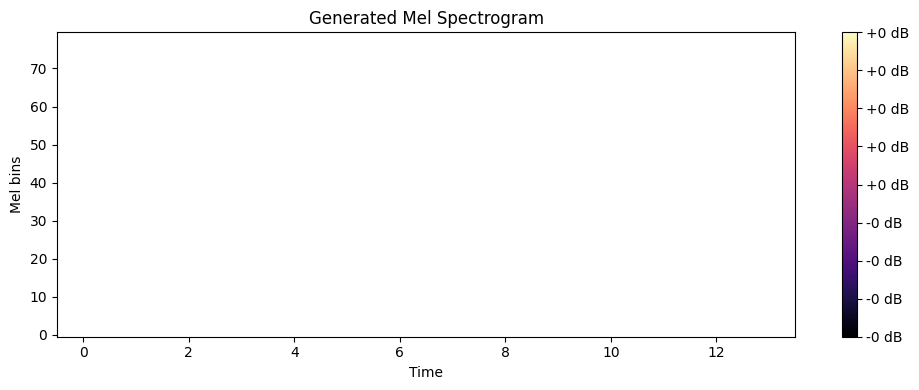

In [37]:
text = "this is a test"
text_seq = torch.tensor([text_to_sequence(text)])

model.eval()
with torch.no_grad():
    # Step 1: Text encoding and projection only
    text_features = model.text_encoder(text_seq)               # (1, T, hidden_dim)
    projected = model.text_to_mel_proj(text_features)          # (1, T, mel_dim)
    
    # Step 2: Apply diffusion blocks manually without noise
    predicted_mel = projected
    for step, block in enumerate(model.mel_generator.diffusion_blocks):
        predicted_mel = block(predicted_mel, step, add_noise=False)

    # Step 3: Convert to (1, mel_dim, T) for Griffin-Lim
    predicted_mel = predicted_mel.transpose(1, 2)

    # Step 4: Generate waveform and save
    waveform = mel_to_waveform(predicted_mel)
    # torchaudio.save("generated.wav", waveform, sample_rate=16000)
    # waveform: Tensor of shape (1, T)
    num_samples = waveform.shape[1]
    duration_sec = num_samples / 16000  # sample_rate = 16000

    print(f"Waveform length: {num_samples} samples")
    print(f"Duration: {duration_sec:.2f} seconds")

    # Create a new mel spectrogram from the generated waveform
    mel_transform = T.MelSpectrogram(
        sample_rate=16000,
        n_fft=1024,
        hop_length=256,
        n_mels=80
    )

    generated_mel = mel_transform(waveform)  # (1, mel_dim, time)

    # Convert to decibels for visualization
    mel_db = torchaudio.transforms.AmplitudeToDB()(generated_mel)

    # Plot
    plt.figure(figsize=(10, 4))
    plt.imshow(mel_db[0].numpy(), origin="lower", aspect="auto", cmap="magma")
    plt.title("Generated Mel Spectrogram")
    plt.xlabel("Time")
    plt.ylabel("Mel bins")
    plt.colorbar(format="%+2.0f dB")
    plt.tight_layout()
    plt.show()



Waveform length: 35584 samples
Duration: 2.22 seconds


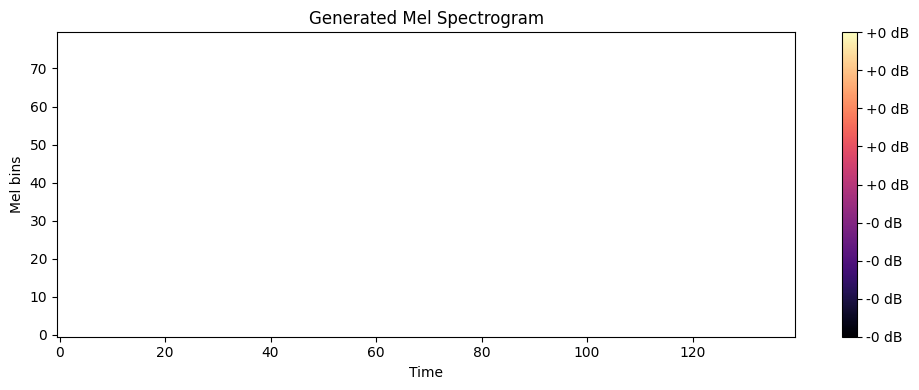

In [36]:
# Inference: Use the full model forward pass
text = "this is a test"
text_seq = torch.tensor([text_to_sequence(text)])  # (1, T_text)

model.eval()
with torch.no_grad():
    # Use the full forward pass which includes the duration predictor and length regulator.
    predicted_mel = model(text_seq)  # (1, T_mel, mel_dim)
    
    # For vocoding (Griffin-Lim), transpose to (1, mel_dim, T_mel)
    predicted_mel = predicted_mel.transpose(1, 2)
    
    # Generate waveform from the mel spectrogram
    waveform = mel_to_waveform(predicted_mel)
    
    # Optionally, save the generated audio
    torchaudio.save("generated.wav", waveform, sample_rate=16000)
    
    # Print waveform info
    num_samples = waveform.shape[1]
    duration_sec = num_samples / 16000
    print(f"Waveform length: {num_samples} samples")
    print(f"Duration: {duration_sec:.2f} seconds")
    
    # For visualization, compute a mel spectrogram from the waveform
    mel_transform = T.MelSpectrogram(
        sample_rate=16000,
        n_fft=1024,
        hop_length=256,
        n_mels=80
    )
    generated_mel = mel_transform(waveform)  # (1, mel_dim, T)
    mel_db = torchaudio.transforms.AmplitudeToDB()(generated_mel)
    
    # Plot the generated mel spectrogram
    plt.figure(figsize=(10, 4))
    plt.imshow(mel_db[0].numpy(), origin="lower", aspect="auto", cmap="magma")
    plt.title("Generated Mel Spectrogram")
    plt.xlabel("Time")
    plt.ylabel("Mel bins")
    plt.colorbar(format="%+2.0f dB")
    plt.tight_layout()
    plt.show()
